# AI Semiconductor Supply Chain Analytics & Packaging Backlog Prediction

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn lightgbm catboost joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

import joblib

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the original synthetic facility dataset.
# Keep the CSV in the same folder as this notebook.
file_path = Path("global_ai_semiconductor_supply_chain.csv")
if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path.resolve()}. "
        "Place global_ai_semiconductor_supply_chain.csv beside the notebook."
    )

df = pd.read_csv(file_path)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 29)


,facility_id,company_name,country_location,facility_type,process_node_nm,wafer_size_mm,monthly_capacity_wafers,capacity_utilization_pct,die_yield_pct,defect_density_per_cm2,lithography_technology,lithography_tool_supplier,lithography_lead_time_months,advanced_packaging_type,hbm_integration_spec,packaging_backlog_weeks,power_consumption_mw,water_recycling_rate_pct,export_restriction_tier,geopolitical_risk_index,target_ai_accelerator_family,supply_chain_vulnerability_score,advanced_node_tier,foundry_market_power_index,chiplet_disaggregation_readiness,hbm_bandwidth_tb_s,ai_wafer_allocation_priority,cot_semiconductor_risk_rationale,confidence_score
0,FAB-SMIC-00CCF968,SMIC,China,Foundry,7nm,300,90373,82.0,94.3,0.079,DUV_Immersion_ArFi,Nikon,14,InFO-PoP,HBM3e,19,163.4,94.0,Strict_ITAR_BIS_Control,8.4,AWS Trainium 2,62.38,Advanced_FinFET_4nm_7nm,4.6,Hybrid_Modular,1.20,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-00CCF968' yang dioperasika...,0.975
1,FAB-SMIC-02D12E75,SMIC,China,Foundry,7nm,300,61469,86.3,93.9,0.092,DUV_Immersion_ArFi,ASML,15,Standard_FlipChip,HBM3,5,110.2,93.6,Strict_ITAR_BIS_Control,9.5,Custom Hyperscaler ASIC,58.73,Advanced_FinFET_4nm_7nm,4.6,Monolithic_Die,0.82,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-02D12E75' yang dioperasika...,0.979
2,FAB-SMIC-03578D8E,SMIC,China,Foundry,12nm,300,85323,79.2,94.6,0.039,DUV_Dry,ASML,15,Standard_FlipChip,NaN,5,145.6,83.2,Strict_ITAR_BIS_Control,7.2,Google TPU v5 / v6,50.68,Mature_Planar_Nodes,4.6,Monolithic_Die,0.00,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-03578D8E' yang dioperasika...,0.977
3,FAB-SMIC-03BC7BA8,SMIC,China,Foundry,7nm,300,58588,75.7,87.8,0.084,Standard_0.33NA_EUV,ASML,16,Standard_FlipChip,NaN,6,98.5,82.7,Strict_ITAR_BIS_Control,9.2,NVIDIA Hopper H100 / H200,59.10,Advanced_FinFET_4nm_7nm,4.6,Monolithic_Die,0.00,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-03BC7BA8' yang dioperasika...,0.981
4,FAB-SMIC-04E97DBE,SMIC,China,Foundry,5nm,300,101342,93.7,81.2,0.179,Standard_0.33NA_EUV,ASML,21,CoWoS-L,HBM3e,19,320.0,88.4,Strict_ITAR_BIS_Control,7.6,AWS Trainium 2,65.41,Advanced_FinFET_4nm_7nm,5.2,High_Chiplet_Adoption,1.20,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-04E97DBE' yang dioperasika...,0.923


In [4]:
#inspect dataset structure

# This gives us our first opportunity to examine variable types, data distributions, and potential problems before training a model.

print("Dataset Information:")
df.info()

print("\nColumns:")
print(df.columns.tolist())

print("\nDescriptive Statistics:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   facility_id                       10000 non-null  object 
 1   company_name                      10000 non-null  object 
 2   country_location                  10000 non-null  object 
 3   facility_type                     10000 non-null  object 
 4   process_node_nm                   10000 non-null  object 
 5   wafer_size_mm                     10000 non-null  int64  
 6   monthly_capacity_wafers           10000 non-null  int64  
 7   capacity_utilization_pct          10000 non-null  float64
 8   die_yield_pct                     10000 non-null  float64
 9   defect_density_per_cm2            10000 non-null  float64
 10  lithography_technology            10000 non-null  object 
 11  lithography_tool_supplier         10000 non-nul

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
facility_id,10000,10000,FAB-SMIC-00CCF968,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_name,10000,10,TSMC,3221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_location,10000,9,USA,2798,NaN,NaN,NaN,NaN,NaN,NaN,NaN
facility_type,10000,5,Foundry,4461,NaN,NaN,NaN,NaN,NaN,NaN,NaN
process_node_nm,10000,7,3nm,2456,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wafer_size_mm,10000.0,NaN,NaN,NaN,299.77,4.790553,200.0,300.0,300.0,300.0,300.0
monthly_capacity_wafers,10000.0,NaN,NaN,NaN,55014.7232,31136.248061,12000.0,26253.25,48402.5,80629.0,145000.0
capacity_utilization_pct,10000.0,NaN,NaN,NaN,93.85524,5.927342,72.0,92.9,95.3,97.6,100.0
die_yield_pct,10000.0,NaN,NaN,NaN,80.30158,10.577484,52.0,73.6,82.2,88.4,98.2
defect_density_per_cm2,10000.0,NaN,NaN,NaN,0.172503,0.093609,0.03,0.105,0.152,0.223,0.44


In [5]:
# Check missing values
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(
    missing_values[
        missing_values["Missing Count"] > 0
    ].sort_values("Missing Count", ascending=False)
)

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check facility IDs
print("Unique facilities:", df["facility_id"].nunique())
print("Total records:", len(df))


,Missing Count,Missing Percentage
hbm_integration_spec,1519,15.19


Duplicate rows: 0
Unique facilities: 10000
Total records: 10000


In [6]:
# handle missing values

# Create a working copy
df_clean = df.copy()

# Fill missing categorical values
df_clean["hbm_integration_spec"] = (
    df_clean["hbm_integration_spec"].fillna("Unknown")
)

# Remove exact duplicate rows, if any
df_clean = df_clean.drop_duplicates()

# Validate target
df_clean = df_clean.dropna(
    subset=["packaging_backlog_weeks"]
)

print("Cleaned dataset:", df_clean.shape)
print("Remaining missing values:",
      df_clean.isnull().sum().sum())

Cleaned dataset: (10000, 29)
Remaining missing values: 0


## Exploratory Data Analysis

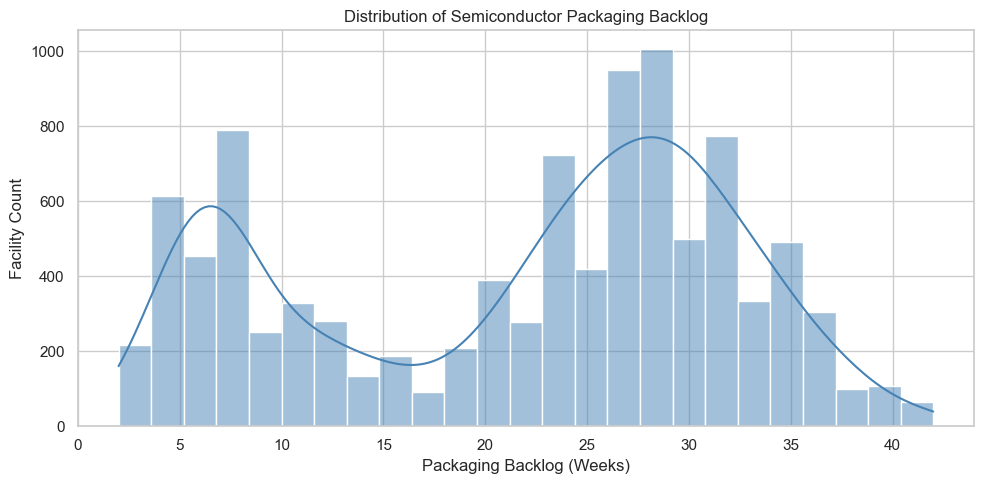

count    10000.000000
mean        21.592900
std         10.568299
min          2.000000
25%         11.000000
50%         25.000000
75%         30.000000
max         42.000000
Name: packaging_backlog_weeks, dtype: float64

In [7]:
# visualize backlog distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    color="steelblue",
    data=df_clean,
    x="packaging_backlog_weeks",
    bins=25,
    kde=True
)

plt.title("Distribution of Semiconductor Packaging Backlog")
plt.xlabel("Packaging Backlog (Weeks)")
plt.ylabel("Facility Count")

plt.tight_layout()
plt.show()

display(
    df_clean["packaging_backlog_weeks"].describe()
)

,mean,median,count
advanced_packaging_type,,,
Foveros-3D,28.187798,28.0,1049
CoWoS-S,28.001507,28.0,2655
CoWoS-L,27.967887,28.0,3114
InFO-PoP,11.420849,11.5,1036
Standard_FlipChip,6.100652,6.0,2146


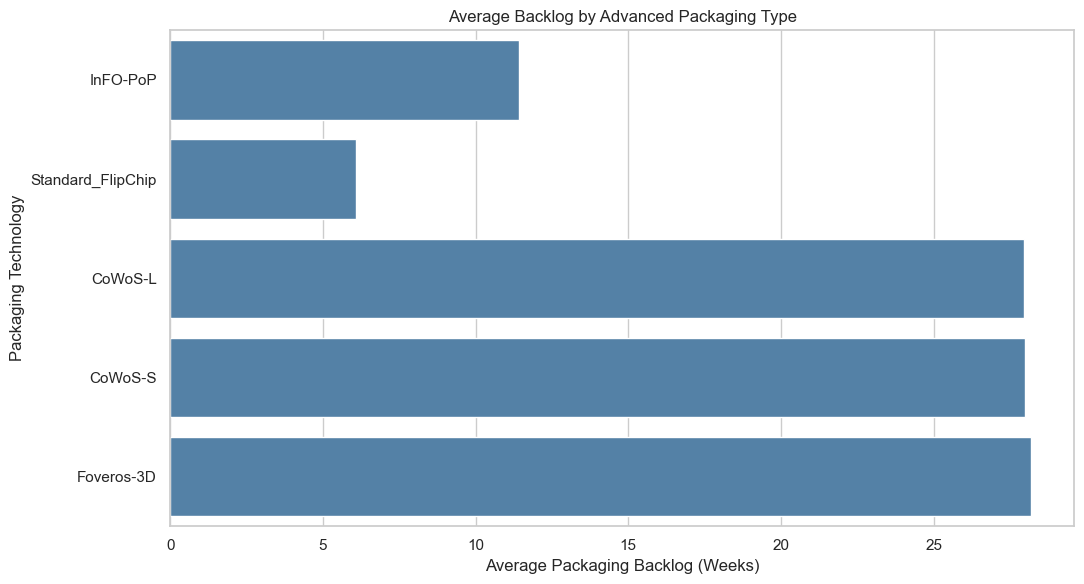

In [8]:
# bar graph of packaging technology vs backlog

packaging_summary = (
    df_clean.groupby("advanced_packaging_type")
    ["packaging_backlog_weeks"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(packaging_summary)

plt.figure(figsize=(11, 6))

sns.barplot(
    color="steelblue",
    data=df_clean,
    x="packaging_backlog_weeks",
    y="advanced_packaging_type",
    estimator=np.mean,
    errorbar=None
)

plt.title("Average Backlog by Advanced Packaging Type")
plt.xlabel("Average Packaging Backlog (Weeks)")
plt.ylabel("Packaging Technology")

plt.tight_layout()
plt.show()

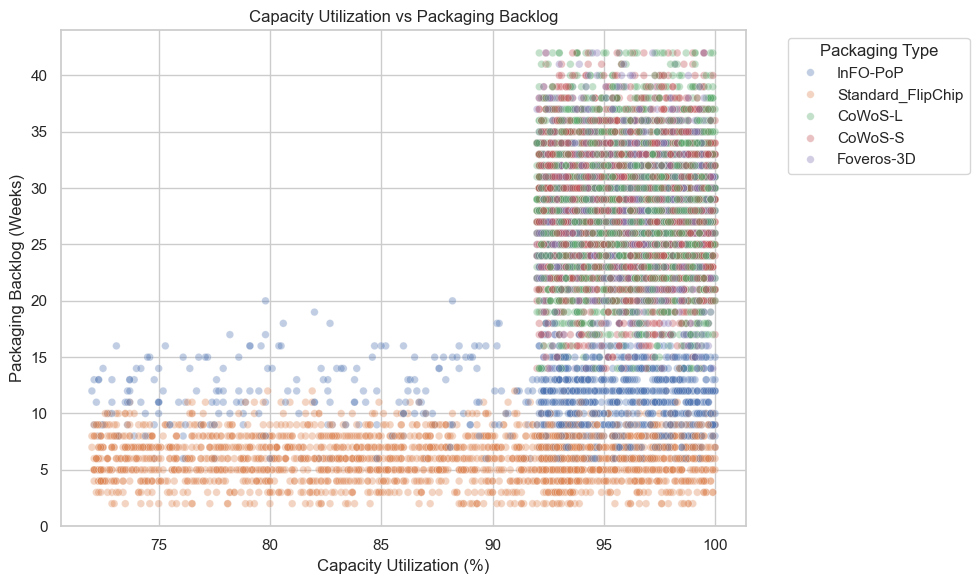

In [9]:
# analyzing relationship between capacity utilization vs backlog


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="capacity_utilization_pct",
    y="packaging_backlog_weeks",
    hue="advanced_packaging_type",
    alpha=0.35,
    s=30
)

plt.title("Capacity Utilization vs Packaging Backlog")
plt.xlabel("Capacity Utilization (%)")
plt.ylabel("Packaging Backlog (Weeks)")
plt.legend(title="Packaging Type", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()


,mean,median,count
country_location,,,
Ireland,24.481013,27.0,158
Netherlands,22.444776,25.0,335
Taiwan,22.153108,25.0,2606
USA,22.003574,25.0,2798
Japan,21.330370,25.0,675
South Korea,21.260314,24.0,2739
Germany,20.566667,24.0,450
Singapore,17.326531,14.0,147
China,8.836957,6.5,92


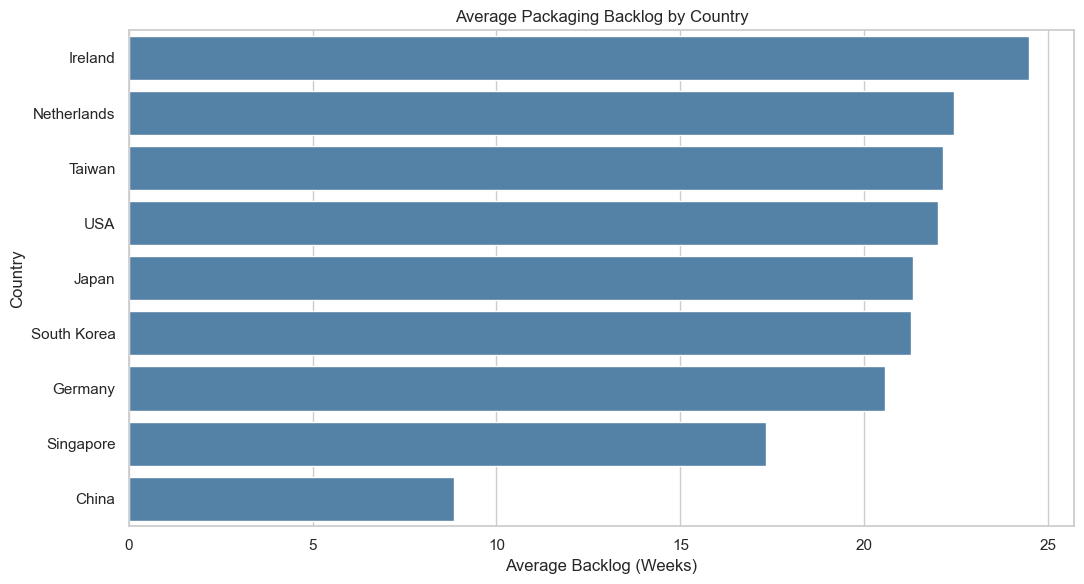

In [10]:
# analyzing backlog by country


country_summary = (
    df_clean.groupby("country_location")
    ["packaging_backlog_weeks"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(country_summary)

plt.figure(figsize=(11, 6))

sns.barplot(
    color="steelblue",
    data=country_summary.reset_index(),
    x="mean",
    y="country_location",
    errorbar=None
)

plt.title("Average Packaging Backlog by Country")
plt.xlabel("Average Backlog (Weeks)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

,mean,count
process_node_nm,,
2nm,24.411487,1271
3nm,24.363599,2456
4nm,24.533143,2097
5nm,24.542762,2093
7nm,10.334125,1263
12nm,10.551155,606
28nm,13.107477,214


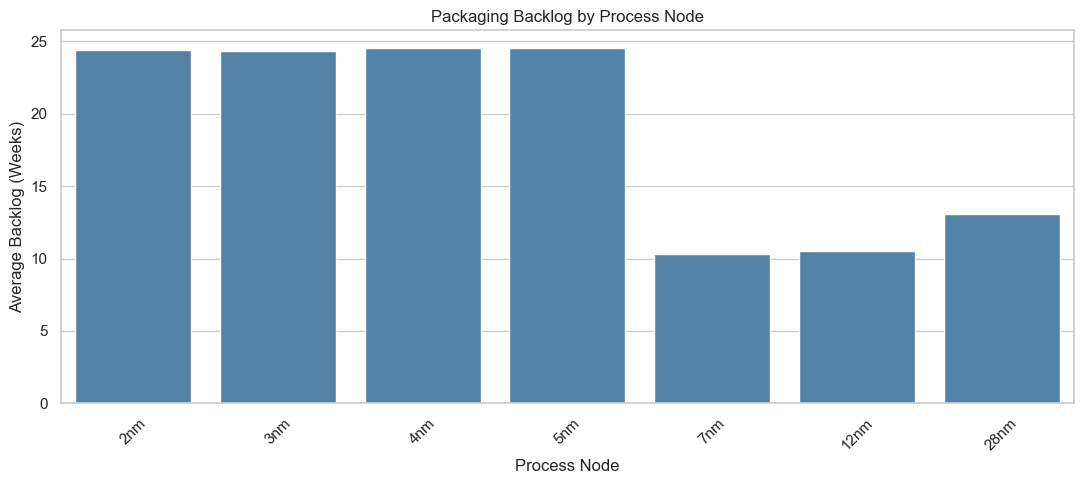

In [14]:

# Analyzing backlog by process node

node_summary = (
    df_clean.groupby("process_node_nm")["packaging_backlog_weeks"]
    .agg(["mean", "count"])
)

# Sort process nodes numerically
node_summary = node_summary.loc[
    sorted(
        node_summary.index,
        key=lambda x: int(x.replace("nm", ""))
    )
]

display(node_summary)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=node_summary.reset_index(),
    x="process_node_nm",
    y="mean",
    color="steelblue",
    errorbar=None
)

plt.title("Packaging Backlog by Process Node")
plt.xlabel("Process Node")
plt.ylabel("Average Backlog (Weeks)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:
# select features


target = "packaging_backlog_weeks"

numeric_features = [
    "wafer_size_mm",
    "monthly_capacity_wafers",
    "capacity_utilization_pct",
    "die_yield_pct",
    "defect_density_per_cm2",
    "lithography_lead_time_months",
    "power_consumption_mw",
    "water_recycling_rate_pct",
    "hbm_bandwidth_tb_s"
]

categorical_features = [
    "company_name",
    "country_location",
    "facility_type",
    "process_node_nm",
    "lithography_technology",
    "lithography_tool_supplier",
    "advanced_packaging_type",
    "hbm_integration_spec",
    "target_ai_accelerator_family"
]

feature_columns = numeric_features + categorical_features

X = df_clean[feature_columns].copy()
y = df_clean[target].copy()

print("Number of predictors:", X.shape[1])
print("Features:", feature_columns)
print("Target:", target)


Number of predictors: 18
Features: ['wafer_size_mm', 'monthly_capacity_wafers', 'capacity_utilization_pct', 'die_yield_pct', 'defect_density_per_cm2', 'lithography_lead_time_months', 'power_consumption_mw', 'water_recycling_rate_pct', 'hbm_bandwidth_tb_s', 'company_name', 'country_location', 'facility_type', 'process_node_nm', 'lithography_technology', 'lithography_tool_supplier', 'advanced_packaging_type', 'hbm_integration_spec', 'target_ai_accelerator_family']
Target: packaging_backlog_weeks


In [16]:
# train/test split and preprocessing


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8000
Testing records: 2000


### Regression Models Training and testing

In [21]:
# train and compare models


from sklearn.model_selection import cross_validate

models = {
    "Dummy Baseline": DummyRegressor(strategy="median"),
    "Bayesian Ridge": BayesianRidge(),
    "LightGBM": LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    ),
    "CatBoost": CatBoostRegressor(
        iterations=250,
        depth=6,
        learning_rate=0.05,
        random_seed=42,
        verbose=False,
        thread_count=2
    )
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for model_name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    results.append({
        "Model": model_name,
        "CV_RMSE": -scores["test_rmse"].mean(),
        "CV_MAE": -scores["test_mae"].mean(),
        "CV_R2": scores["test_r2"].mean()
    })

    print(model_name, "completed")

model_results = pd.DataFrame(results).sort_values(
    "CV_RMSE"
).reset_index(drop=True)

display(model_results.round(4))

Dummy Baseline completed
Bayesian Ridge completed
LightGBM completed
CatBoost completed


,Model,CV_RMSE,CV_MAE,CV_R2
0,Bayesian Ridge,4.6310,3.5338,0.8079
1,CatBoost,4.6459,3.5464,0.8067
2,LightGBM,4.7258,3.6084,0.7999
3,Dummy Baseline,11.1024,8.8461,-0.1036


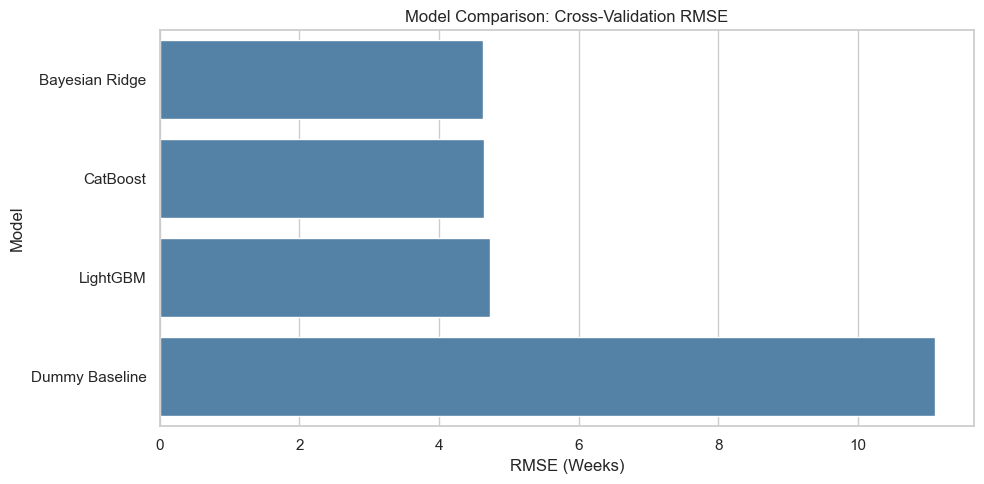

In [22]:
# visualize model comparision

plt.figure(figsize=(10, 5))

sns.barplot(
    color="steelblue",
    data=model_results,
    x="CV_RMSE",
    y="Model",
    errorbar=None
)

plt.title("Model Comparison: Cross-Validation RMSE")
plt.xlabel("RMSE (Weeks)")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

In [23]:
# Select and train the best model

best_model_name = model_results.iloc[0]["Model"]

print("Best model:", best_model_name)

best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", models[best_model_name])
])

best_pipeline.fit(X_train, y_train)

print("Model training completed successfully.")

Best model: Bayesian Ridge
Model training completed successfully.


### Model Evaluation

In [24]:
# generate test predictions

y_pred = best_pipeline.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Best Model:", best_model_name)
print(f"Test RMSE: {rmse:.3f} weeks")
print(f"Test MAE: {mae:.3f} weeks")
print(f"Test R²: {r2:.3f}")

Best Model: Bayesian Ridge
Test RMSE: 4.642 weeks
Test MAE: 3.506 weeks
Test R²: 0.806


### Packaging-Type Baseline Comparison

Compare the selected regression model against a simple benchmark that predicts each facility's backlog from the **training-set average** of its packaging technology. Both methods are evaluated on the same held-out test records. This checks whether adding other manufacturing features improves predictive accuracy beyond packaging type alone.

In [25]:
packaging_means = (
    pd.DataFrame({
        "packaging_type": X_train["advanced_packaging_type"],
        "backlog_weeks": y_train
    })
    .groupby("packaging_type")["backlog_weeks"]
    .mean()
)

baseline_pred = (
    X_test["advanced_packaging_type"]
    .map(packaging_means)
    .fillna(y_train.mean())
    .to_numpy()
)

baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)

baseline_comparison = pd.DataFrame([
    {"Model": "Packaging Type Average (baseline)",
     "MAE": baseline_mae, "RMSE": baseline_rmse, "R2": baseline_r2},
    {"Model": best_model_name,
     "MAE": mae, "RMSE": rmse, "R2": r2}
])

display(baseline_comparison.round(4))
print(f"RMSE improvement of {best_model_name} over packaging baseline: "
      f"{baseline_rmse - rmse:+.4f} weeks")
print("Positive = selected regression model performs better; "
      "negative = packaging baseline performs better.")

,Model,MAE,RMSE,R2
0,Packaging Type Average (baseline),3.4855,4.6327,0.8073
1,Bayesian Ridge,3.5063,4.6425,0.8065


RMSE improvement of Bayesian Ridge over packaging baseline: -0.0098 weeks
Positive = selected regression model performs better; negative = packaging baseline performs better.


**Model Interpretation:** Bayesian Ridge achieved an R² of approximately 0.806 on the holdout test set. However, a simpler packaging-type average baseline performed slightly better, indicating that packaging technology accounts for most of the predictive information in the dataset.
Additional manufacturing characteristics did not demonstrate a meaningful improvement in accuracy.

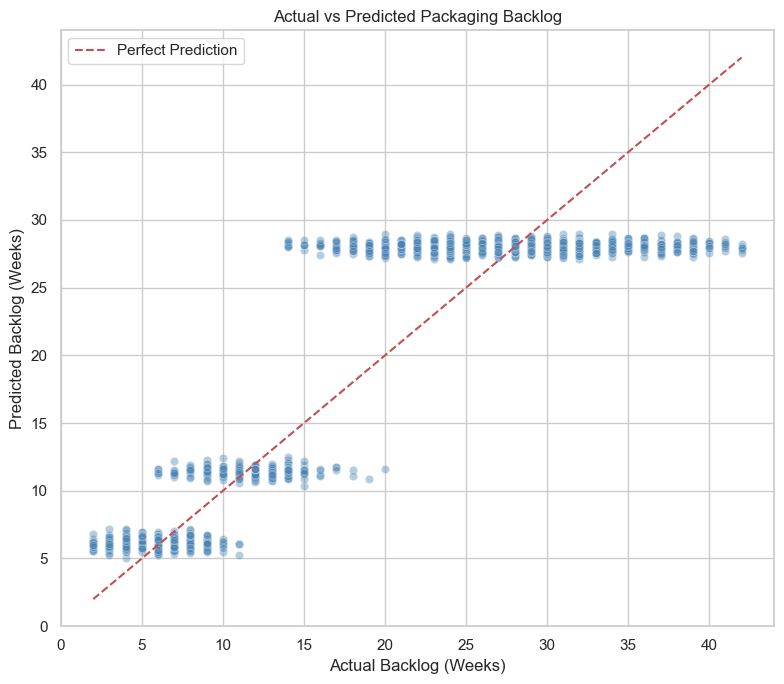

In [26]:
# Actual vs. predicted backlog

plt.figure(figsize=(8, 7))

sns.scatterplot(
    color="steelblue",
    x=y_test,
    y=y_pred,
    alpha=0.4
)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, "r--", label="Perfect Prediction")

plt.title("Actual vs Predicted Packaging Backlog")
plt.xlabel("Actual Backlog (Weeks)")
plt.ylabel("Predicted Backlog (Weeks)")
plt.legend()

plt.tight_layout()
plt.show()

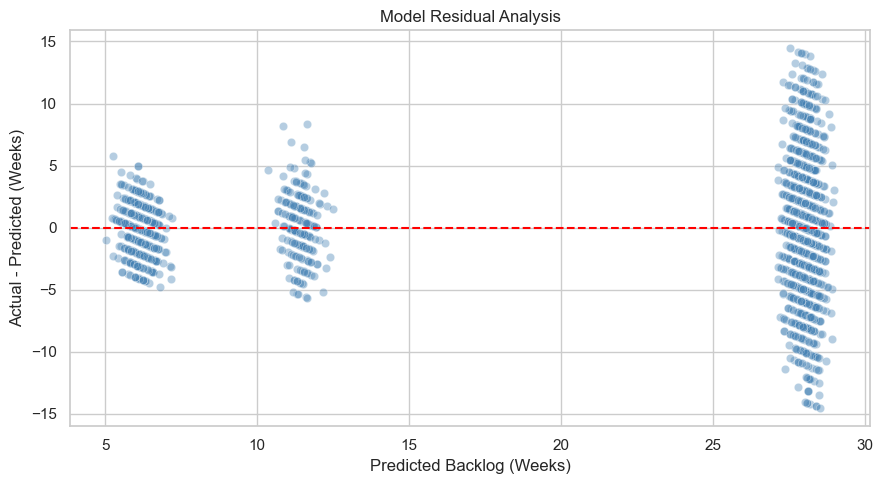

In [27]:
# residual analysis


residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(9, 5))

sns.scatterplot(
    color="steelblue",
    x=y_pred,
    y=residuals,
    alpha=0.4
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Model Residual Analysis")
plt.xlabel("Predicted Backlog (Weeks)")
plt.ylabel("Actual - Predicted (Weeks)")

plt.tight_layout()
plt.show()


,Feature,Importance
15,advanced_packaging_type,9.724631
12,process_node_nm,0.020842
4,defect_density_per_cm2,0.019272
1,monthly_capacity_wafers,0.013227
9,company_name,0.004628
17,target_ai_accelerator_family,0.004463
10,country_location,0.004030
13,lithography_technology,0.003361
8,hbm_bandwidth_tb_s,0.001337
11,facility_type,0.001105


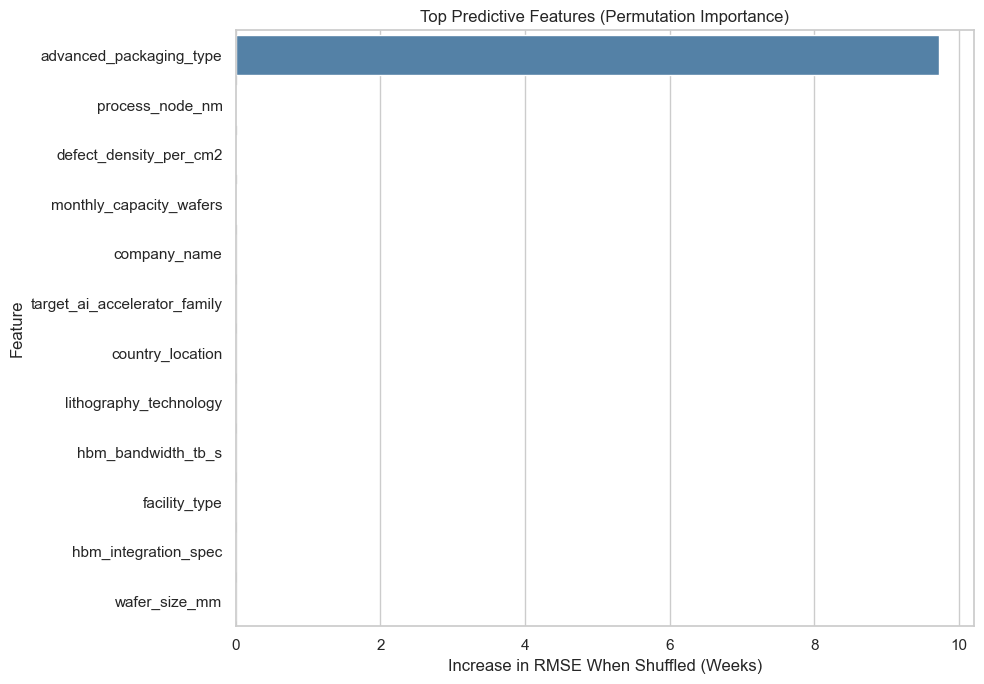

In [28]:
# Feature importance
# We can use permutation importance, which measures how much predictive performance deteriorates when a feature is shuffled.


from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_pipeline,
    X_test,
    y_test,
    n_repeats=3,
    random_state=42,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 7))

sns.barplot(
    color="steelblue",
    data=importance_df.head(12),
    x="Importance",
    y="Feature",
    errorbar=None
)

plt.title("Top Predictive Features (Permutation Importance)")
plt.xlabel("Increase in RMSE When Shuffled (Weeks)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()